# NetGuardAI - Module 1: Data Ingestion and Preprocessing

**Project:** NetGuardAI | FYP-1 | FAST-NUCES  
**Dataset:** GeNIS - GECAD Network Intrusion Scenarios (2025)  
**Zenodo:** https://zenodo.org/records/14919237  
**Citation:** https://doi.org/10.1016/j.dib.2025.111487

---

### Module 1 Task Breakdown

| Task | Name | Scientific Requirement |
|------|------|------------------------|
| T1.1 | Dataset Acquisition | Acquire the 60-second flow CSV files from the GeNIS preprocessed archive |
| T1.2 | Data Loading & Inspection | Use the official training partition for development; retain official test partition for final independent evaluation |
| T1.3 | Exploratory Data Analysis (EDA) | Inspect distributions, correlations, missing values, and feature distributions |
| T1.4 | Target Isolation & Stratified Split | Split the official training partition into 70/15/15 before fitting feature transformers; exclude all label tiers from predictors |
| T1.5 | Feature Engineering | Fit imputers and encoders on training data only |
| T1.6 | Normalization | Fit the scaler on training data only |
| T1.7 | Class Imbalance Report | Report class counts and ratios without mislabeling benign traffic as an attack |
| T1.8 | Baseline Benchmark | Evaluate an unaugmented Random Forest on the real internal held-out test split |

The notebook's 70/15/15 test split is an **internal holdout drawn from the official training file**. The official GeNIS test partition is kept separate for a later independent evaluation and is not used to fit, tune, or score this baseline.


---
## Setup — Install and Import All Libraries

In [1]:
# Install required libraries (only needed in Google Colab)
!pip install -q pandas numpy matplotlib seaborn scikit-learn requests

In [2]:
import os
import json
import zipfile
import warnings
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')

# Global plot style
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Colab vs Local directory handling
BASE_DIR = '/content' if os.path.exists('/content') else '.'
EXTRACT_DIR = os.path.join(BASE_DIR, 'genis_data')
ZIP_PATH = os.path.join(BASE_DIR, 'genis_preprocessed.zip')

print('All libraries imported successfully.')
print(f'Pandas  : {pd.__version__}')
print(f'NumPy   : {np.__version__}')
print(f'Working directory: {os.path.abspath(BASE_DIR)}')

All libraries imported successfully.
Pandas  : 2.2.3
NumPy   : 2.1.3
Working directory: /content


---
## T1.1 — Dataset Acquisition

We download the **preprocessed CSV variant** (`4-preprocessed.zip`, ~600 MB) from Zenodo Record 14919237.  
This variant provides filtered network flow features aggregated over 5s, 10s, 30s, and 60s intervals.

In [3]:
# Zenodo direct download URL - preprocessed CSV variant
ZENODO_URL = 'https://zenodo.org/records/14919237/files/4-preprocessed.zip?download=1'

os.makedirs(EXTRACT_DIR, exist_ok=True)

def download_file(url, save_path, chunk_size=8 * 1024 * 1024, max_retries=6):
    """Download a large ZIP in resumable HTTP byte ranges with retries."""
    import re
    import time

    partial_path = save_path + '.part'

    # A complete ZIP is safe to reuse. A size-only check can mistake an
    # interrupted download for a finished archive, so validate the ZIP itself.
    if os.path.exists(save_path):
        if zipfile.is_zipfile(save_path):
            print(f'Archive already complete: {save_path} ({os.path.getsize(save_path)/(1024*1024):.1f} MB)')
            return
        # Preserve the previous downloader's interrupted file and resume it.
        if not os.path.exists(partial_path) or os.path.getsize(save_path) > os.path.getsize(partial_path):
            os.replace(save_path, partial_path)
        else:
            os.remove(save_path)

    # HEAD gives the total size without downloading the archive body.
    head = requests.head(url, allow_redirects=True, timeout=(30, 60),
                         headers={'Accept-Encoding': 'identity'})
    head.raise_for_status()
    total_size = int(head.headers.get('Content-Length', 0))
    if total_size <= 0:
        raise RuntimeError('Could not determine archive size from Zenodo; download was not started.')

    downloaded = os.path.getsize(partial_path) if os.path.exists(partial_path) else 0
    if downloaded > total_size:
        raise RuntimeError(f'Partial file is larger than the archive ({downloaded} > {total_size} bytes).')

    if downloaded == total_size and zipfile.is_zipfile(partial_path):
        os.replace(partial_path, save_path)
        print(f'Completed existing partial archive: {save_path}')
        return

    print(f'Downloading/resuming archive: {downloaded:,} / {total_size:,} bytes already present.')
    while downloaded < total_size:
        requested_end = min(downloaded + chunk_size - 1, total_size - 1)
        for attempt in range(1, max_retries + 1):
            response = None
            try:
                response = requests.get(
                    url,
                    headers={
                        'Range': f'bytes={downloaded}-{requested_end}',
                        'Accept-Encoding': 'identity',
                    },
                    stream=True,
                    allow_redirects=True,
                    timeout=(30, 120),
                )
                if response.status_code in (408, 429) or 500 <= response.status_code < 600:
                    raise requests.exceptions.HTTPError(
                        f'Zenodo temporarily returned HTTP {response.status_code} for this byte range.',
                        response=response,
                    )
                if response.status_code != 206:
                    raise RuntimeError(f'Zenodo did not honor the byte-range request (HTTP {response.status_code}).')

                match = re.fullmatch(r'bytes (\d+)-(\d+)/(\d+)', response.headers.get('Content-Range', ''))
                if not match:
                    raise RuntimeError(f'Invalid Content-Range returned by Zenodo: {response.headers.get("Content-Range")}')
                range_start, range_end, range_total = map(int, match.groups())
                if range_start != downloaded or range_end > requested_end or range_total != total_size:
                    raise RuntimeError('Zenodo returned a mismatched byte range; refusing to corrupt the partial file.')

                expected_bytes = range_end - range_start + 1
                payload = b''.join(response.iter_content(chunk_size=1024 * 1024))
                if len(payload) != expected_bytes:
                    raise requests.exceptions.ChunkedEncodingError(
                        f'Incomplete range: received {len(payload)} of {expected_bytes} bytes.'
                    )

                with open(partial_path, 'ab') as archive:
                    archive.write(payload)
                downloaded += len(payload)
                pct = downloaded / total_size * 100
                print(f'  Progress: {pct:5.1f}% ({downloaded/(1024*1024):.1f}/{total_size/(1024*1024):.1f} MB)', end='\r')
                break
            except requests.exceptions.RequestException as exc:
                if attempt == max_retries:
                    raise RuntimeError(
                        f'Download stopped at {downloaded:,}/{total_size:,} bytes after {max_retries} retries. '
                        f'Rerun this cell to resume. Last error: {exc}'
                    ) from exc
                wait_seconds = min(2 ** (attempt - 1), 30)
                if isinstance(exc, requests.exceptions.HTTPError) and exc.response is not None:
                    retry_after = exc.response.headers.get('Retry-After')
                    if retry_after:
                        try:
                            wait_seconds = min(max(float(retry_after), 0), 120)
                        except ValueError:
                            pass  # Fall back to exponential backoff for HTTP-date values.
                print(f'\n  Range request failed ({exc}); retrying in {wait_seconds:g}s '
                      f'({attempt}/{max_retries})...')
                time.sleep(wait_seconds)
            finally:
                if response is not None:
                    response.close()

    print()
    if not zipfile.is_zipfile(partial_path):
        raise RuntimeError('Download reached the expected size, but the result is not a valid ZIP archive.')
    os.replace(partial_path, save_path)
    print(f'Download complete and ZIP-validated: {save_path} ({os.path.getsize(save_path)/(1024*1024):.1f} MB)')

download_file(ZENODO_URL, ZIP_PATH)

# Extract ZIP
print('Extracting ZIP archive...')
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    contents = z.namelist()
    print(f'Files inside archive ({len(contents)} total):')
    for item in contents[:10]:
        print(f'  - {item}')
    if len(contents) > 10:
        print(f'  ... and {len(contents)-10} more files')
    z.extractall(EXTRACT_DIR)
print(f'Extraction complete to: {EXTRACT_DIR}')


Downloading/resuming archive: 0 / 599,956,349 bytes already present.
  Progress: 100.0% (572.2/572.2 MB)
Download complete and ZIP-validated: /content/genis_preprocessed.zip (572.2 MB)
Extracting ZIP archive...
Files inside archive (9 total):
  - 4-preprocessed/
  - 4-preprocessed/genis-10-sec-test.csv
  - 4-preprocessed/genis-10-sec-train.csv
  - 4-preprocessed/genis-30-sec-test.csv
  - 4-preprocessed/genis-30-sec-train.csv
  - 4-preprocessed/genis-5-sec-test.csv
  - 4-preprocessed/genis-5-sec-train.csv
  - 4-preprocessed/genis-60-sec-test.csv
  - 4-preprocessed/genis-60-sec-train.csv


KeyboardInterrupt: 

---
## T1.2 - Data Loading and Scenario Assembly

Use the official 60-second training CSV as the source for the internal 70/15/15 development split. Keep the official 60-second test CSV separate; do not concatenate it into the development data. This preserves an independent dataset partition for a later final evaluation.


In [4]:
# Locate official 60-second training and test files
csv_files = sorted(Path(EXTRACT_DIR).rglob('*.csv'))
train_matches = [f for f in csv_files if f.name == 'genis-60-sec-train.csv']
test_matches = [f for f in csv_files if f.name == 'genis-60-sec-test.csv']
if not train_matches:
    raise FileNotFoundError('Expected genis-60-sec-train.csv in the extracted archive.')
if not test_matches:
    raise FileNotFoundError('Expected genis-60-sec-test.csv in the extracted archive.')
train_csv = train_matches[0]
official_test_csv = test_matches[0]
print(f'Official training source: {train_csv.name} ({train_csv.stat().st_size / (1024*1024):.1f} MB)')
print(f'Official test retained for later independent evaluation: {official_test_csv.name} ({official_test_csv.stat().st_size / (1024*1024):.1f} MB)')
print('Only the official training partition is loaded into the Module 1 development split.')

df = pd.read_csv(train_csv, low_memory=False)
print(f"\nDevelopment source loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

Official training source: genis-60-sec-train.csv (122.5 MB)
Official test retained for later independent evaluation: genis-60-sec-test.csv (37.0 MB)
Only the official training partition is loaded into the Module 1 development split.

Development source loaded: 244,019 rows x 87 columns


In [5]:
# Dataset Inspection Report
separator = '=' * 65
print(separator)
print('NETGUARDAI — DATASET INSPECTION REPORT')
print('GeNIS (2025)  |  Module 1 — T1.2')
print(separator)
print(f'Rows    : {df.shape[0]:,}')
print(f'Columns : {df.shape[1]}')

mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
print(f'Memory  : {mem_mb:.2f} MB')

# Check GeNIS multi-tier label columns
KNOWN_LABELS = ['BinaryLabel', 'CategoryLabel', 'SubCategoryLabel']
found_labels = [c for c in KNOWN_LABELS if c in df.columns]
print(f'\nGeNIS Label Tiers Detected: {found_labels}')
for lbl in found_labels:
    print(f'  [{lbl}] Unique values: {df[lbl].nunique()}')
    print(f'    Distribution:\n{df[lbl].value_counts().head(5).to_dict()}')

print(f'\nMISSING VALUES')
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
if len(missing_cols) == 0:
    print('  No missing values found.')
else:
    print(f'  {len(missing_cols)} column(s) have missing values:')
    for col, cnt in missing_cols.items():
        print(f'    {col}: {cnt:,} ({cnt/len(df)*100:.2f}%)')

print(f'\nDUPLICATE ROWS (exact full-row matches)')
dupes = df.duplicated().sum()
print(f'  {dupes:,} duplicate rows ({dupes/len(df)*100:.3f}%)')
print(separator)

NETGUARDAI — DATASET INSPECTION REPORT
GeNIS (2025)  |  Module 1 — T1.2
Rows    : 244,019
Columns : 87
Memory  : 334.09 MB

GeNIS Label Tiers Detected: ['BinaryLabel', 'CategoryLabel', 'SubCategoryLabel']
  [BinaryLabel] Unique values: 2
    Distribution:
{1.0: 226051, 0.0: 17967}
  [CategoryLabel] Unique values: 4
    Distribution:
{'dos': 195648, 'recon': 18446, 'benign': 17967, 'bruteforce': 11957}
  [SubCategoryLabel] Unique values: 13
    Distribution:
{'dos-pushack': 43604, 'dos-icmp': 43368, 'dos-udp': 43361, 'dos-slowloris': 34193, 'dos-hulk': 31122}

MISSING VALUES
  48 column(s) have missing values:
    DAppBytes: 1 (0.00%)
    SIntPktAct: 1 (0.00%)
    PCRatio: 1 (0.00%)
    DstWin: 1 (0.00%)
    dMinPktSz: 1 (0.00%)
    SrcJitAct: 1 (0.00%)
    Offset: 1 (0.00%)
    dMaxPktSz: 1 (0.00%)
    sMeanPktSz: 1 (0.00%)
    DstJitter: 1 (0.00%)
    pLoss: 1 (0.00%)
    SrcJitter: 1 (0.00%)
    Dur: 1 (0.00%)
    Load: 1 (0.00%)
    Ssaddr: 1 (0.00%)
    RunTime: 1 (0.00%)
    Sdadd

---
## T1.3 — Exploratory Data Analysis (EDA)

We produce 4 diagnostic charts:
1. **Class Distribution Bar Chart** (with log scale for minority visibility)
2. **Missing Values Matrix**
3. **Feature Correlation Matrix** (Top 20 numeric features)
4. **Feature Distributions** (Top 9 high-variance traffic features)

Primary Analysis Target: "CategoryLabel"


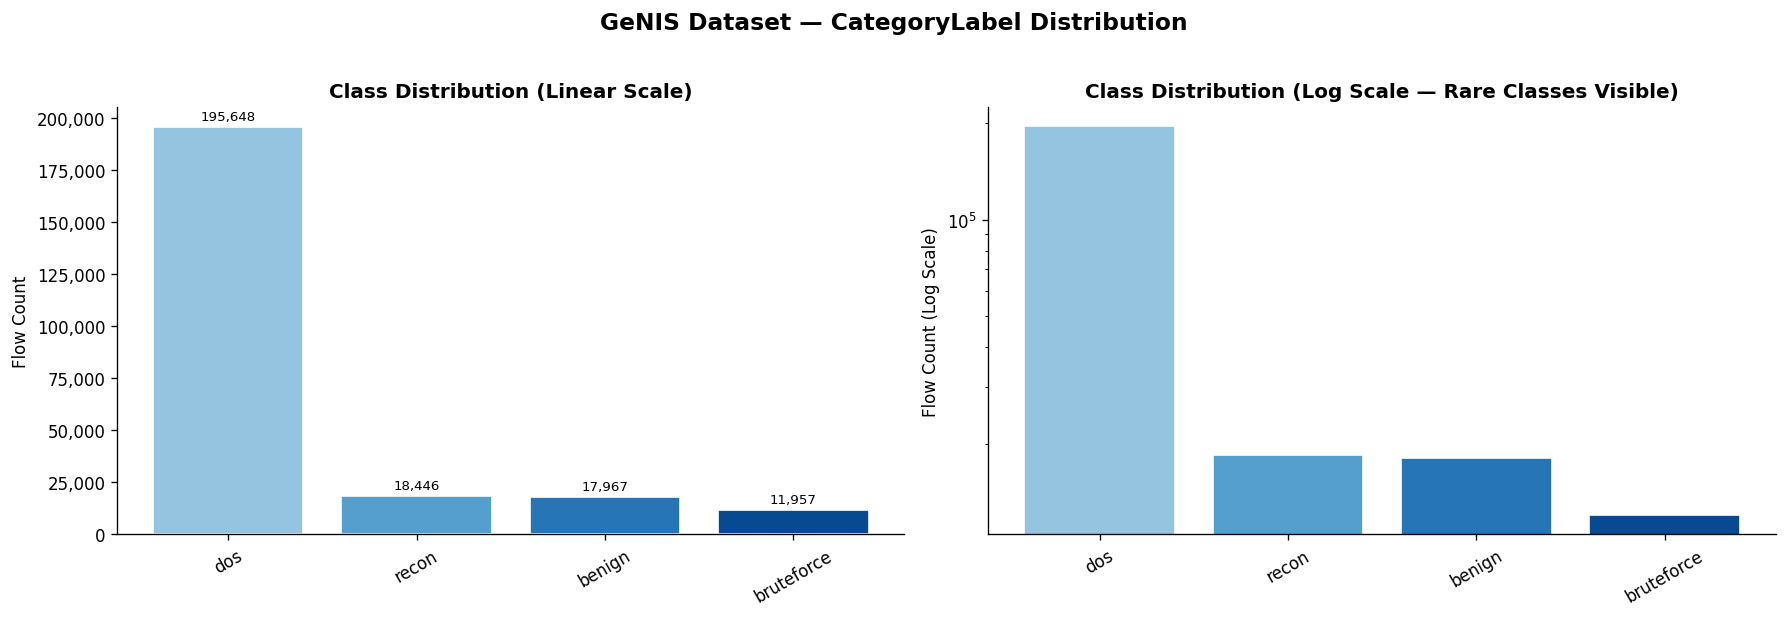

Chart 1 saved: /content/chart1_class_distribution.png


In [6]:
# Select primary target column for analysis
# Primary target: CategoryLabel (Multiclass attack types: Benign, Bruteforce, DoS, Reconnaissance)
if 'CategoryLabel' in df.columns:
    PRIMARY_LABEL = 'CategoryLabel'
elif 'BinaryLabel' in df.columns:
    PRIMARY_LABEL = 'BinaryLabel'
else:
    PRIMARY_LABEL = df.columns[-1]

print(f'Primary Analysis Target: "{PRIMARY_LABEL}"')

# Chart 1 — Class Distribution (Dual View: Linear and Log Scale)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
class_counts = df[PRIMARY_LABEL].value_counts()
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(class_counts)))

# Linear Scale
bars1 = ax1.bar(class_counts.index.astype(str), class_counts.values, color=colors, edgecolor='white')
for bar, val in zip(bars1, class_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + class_counts.max()*0.01,
             f'{val:,}', ha='center', va='bottom', fontsize=8)
ax1.set_title(f'Class Distribution (Linear Scale)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Flow Count')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.tick_params(axis='x', rotation=30)

# Log Scale (Critical for visualizing rare attack classes)
bars2 = ax2.bar(class_counts.index.astype(str), class_counts.values, color=colors, edgecolor='white')
ax2.set_yscale('log')
ax2.set_title(f'Class Distribution (Log Scale — Rare Classes Visible)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Flow Count (Log Scale)')
ax2.tick_params(axis='x', rotation=30)

plt.suptitle(f'GeNIS Dataset — {PRIMARY_LABEL} Distribution', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
chart1_path = os.path.join(BASE_DIR, 'chart1_class_distribution.png')
plt.savefig(chart1_path, bbox_inches='tight')
plt.show()
print(f'Chart 1 saved: {chart1_path}')

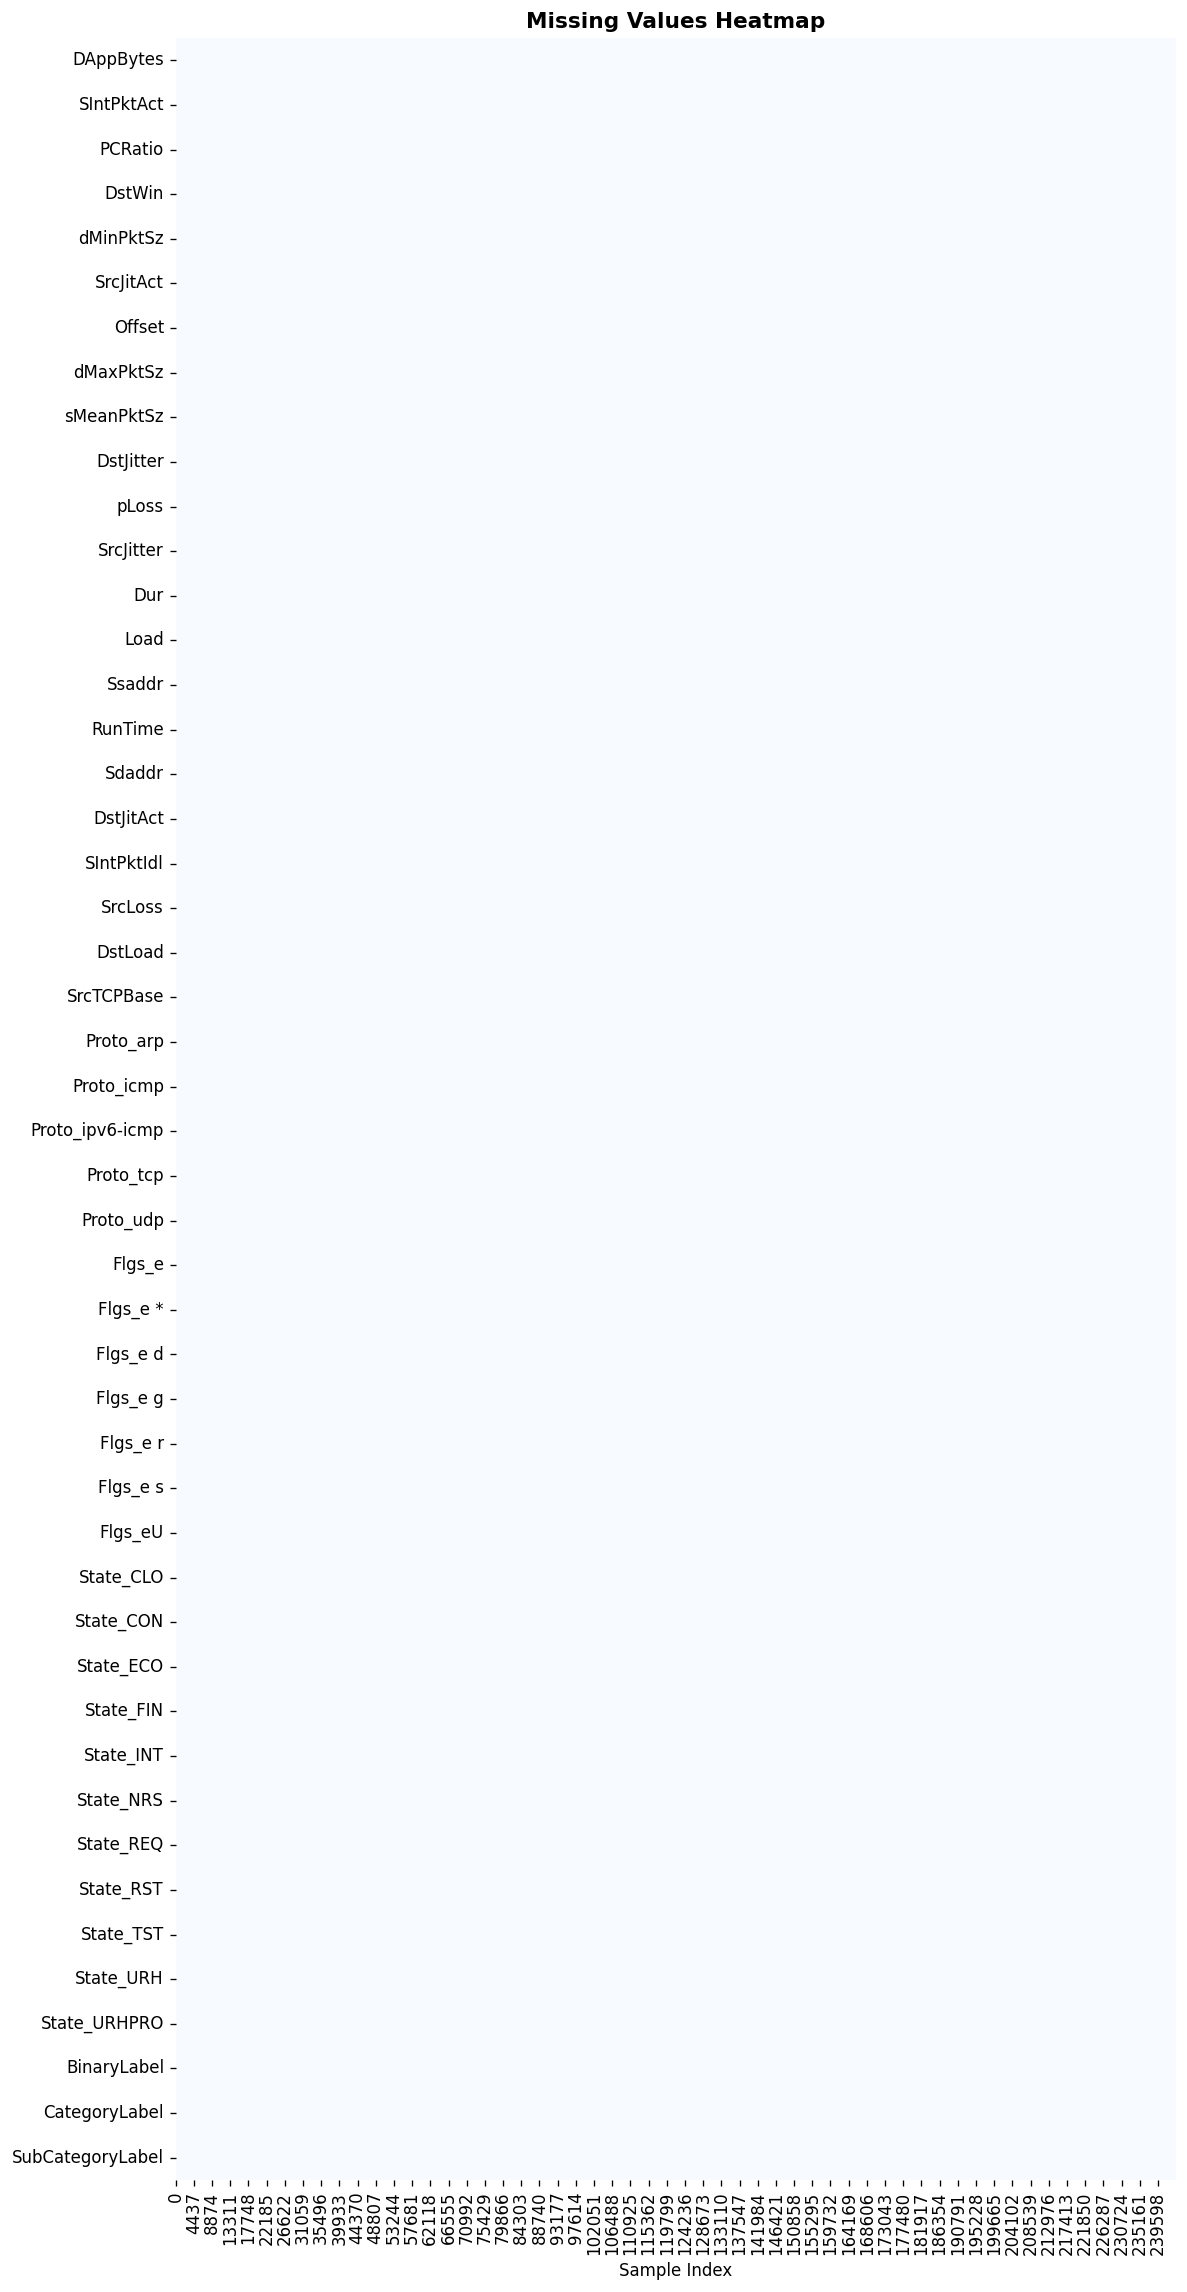

Chart 2 saved: /content/chart2_missing_values.png


In [7]:
# Chart 2 — Missing Values Heatmap
missing_pct = df.isnull().mean() * 100
missing_df = missing_pct[missing_pct > 0].sort_values(ascending=False)

if len(missing_df) == 0:
    print('No missing values in the dataset. Missing values heatmap not required.')
else:
    fig, ax = plt.subplots(figsize=(10, max(4, len(missing_df) * 0.4)))
    missing_matrix = df[missing_df.index].isnull().astype(int)
    sns.heatmap(missing_matrix.T, cbar=False, cmap='Blues', ax=ax, yticklabels=True)
    ax.set_title('Missing Values Heatmap', fontsize=13, fontweight='bold')
    ax.set_xlabel('Sample Index')
    plt.tight_layout()
    chart2_path = os.path.join(BASE_DIR, 'chart2_missing_values.png')
    plt.savefig(chart2_path, bbox_inches='tight')
    plt.show()
    print(f'Chart 2 saved: {chart2_path}')

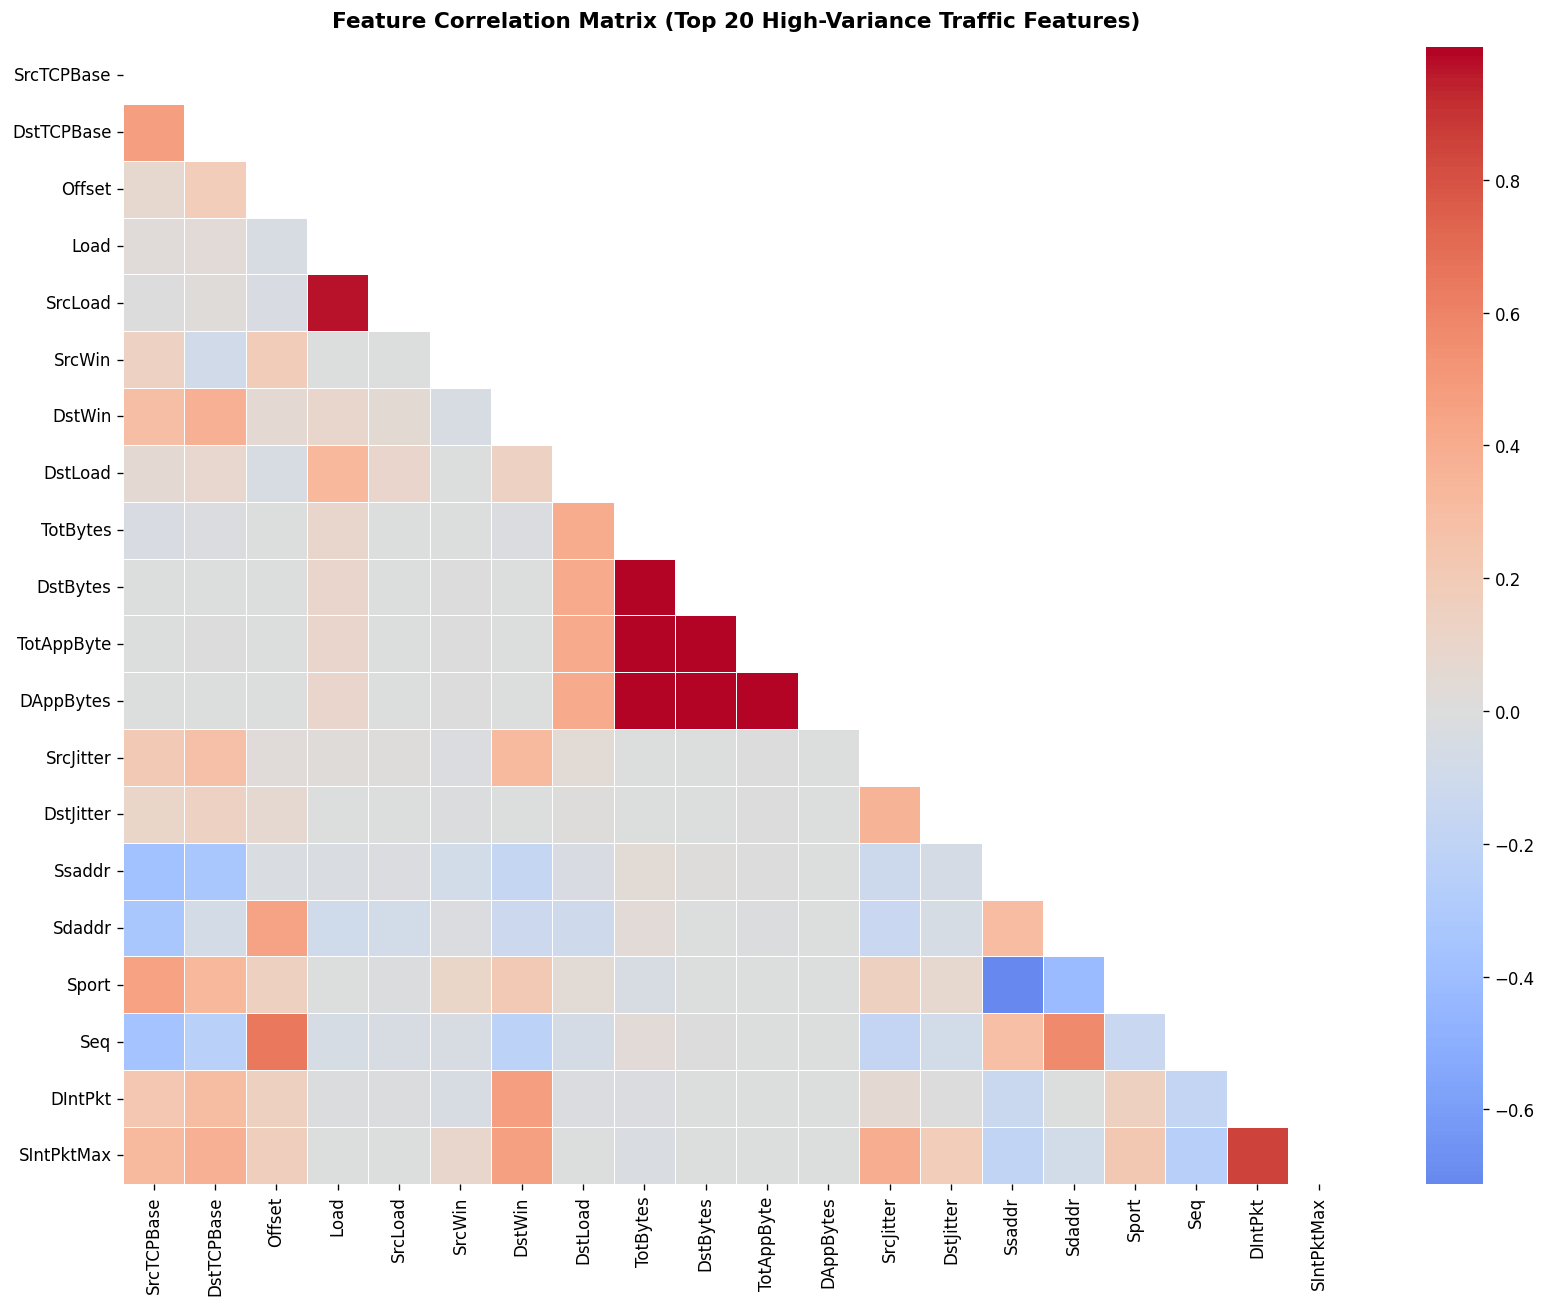

Chart 3 saved: /content/chart3_correlation_matrix.png


In [8]:
# Chart 3 — Feature Correlation Matrix (Top 20 numeric features by variance)
# Exclude label columns before calculating correlation
label_cols_all = ['BinaryLabel', 'CategoryLabel', 'SubCategoryLabel']
num_candidates = [c for c in df.select_dtypes(include=[np.number]).columns if c not in label_cols_all]

top_cols = df[num_candidates].var().nlargest(20).index.tolist()
corr_matrix = df[top_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', center=0, linewidths=0.3, ax=ax)
ax.set_title('Feature Correlation Matrix (Top 20 High-Variance Traffic Features)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
chart3_path = os.path.join(BASE_DIR, 'chart3_correlation_matrix.png')
plt.savefig(chart3_path, bbox_inches='tight')
plt.show()
print(f'Chart 3 saved: {chart3_path}')

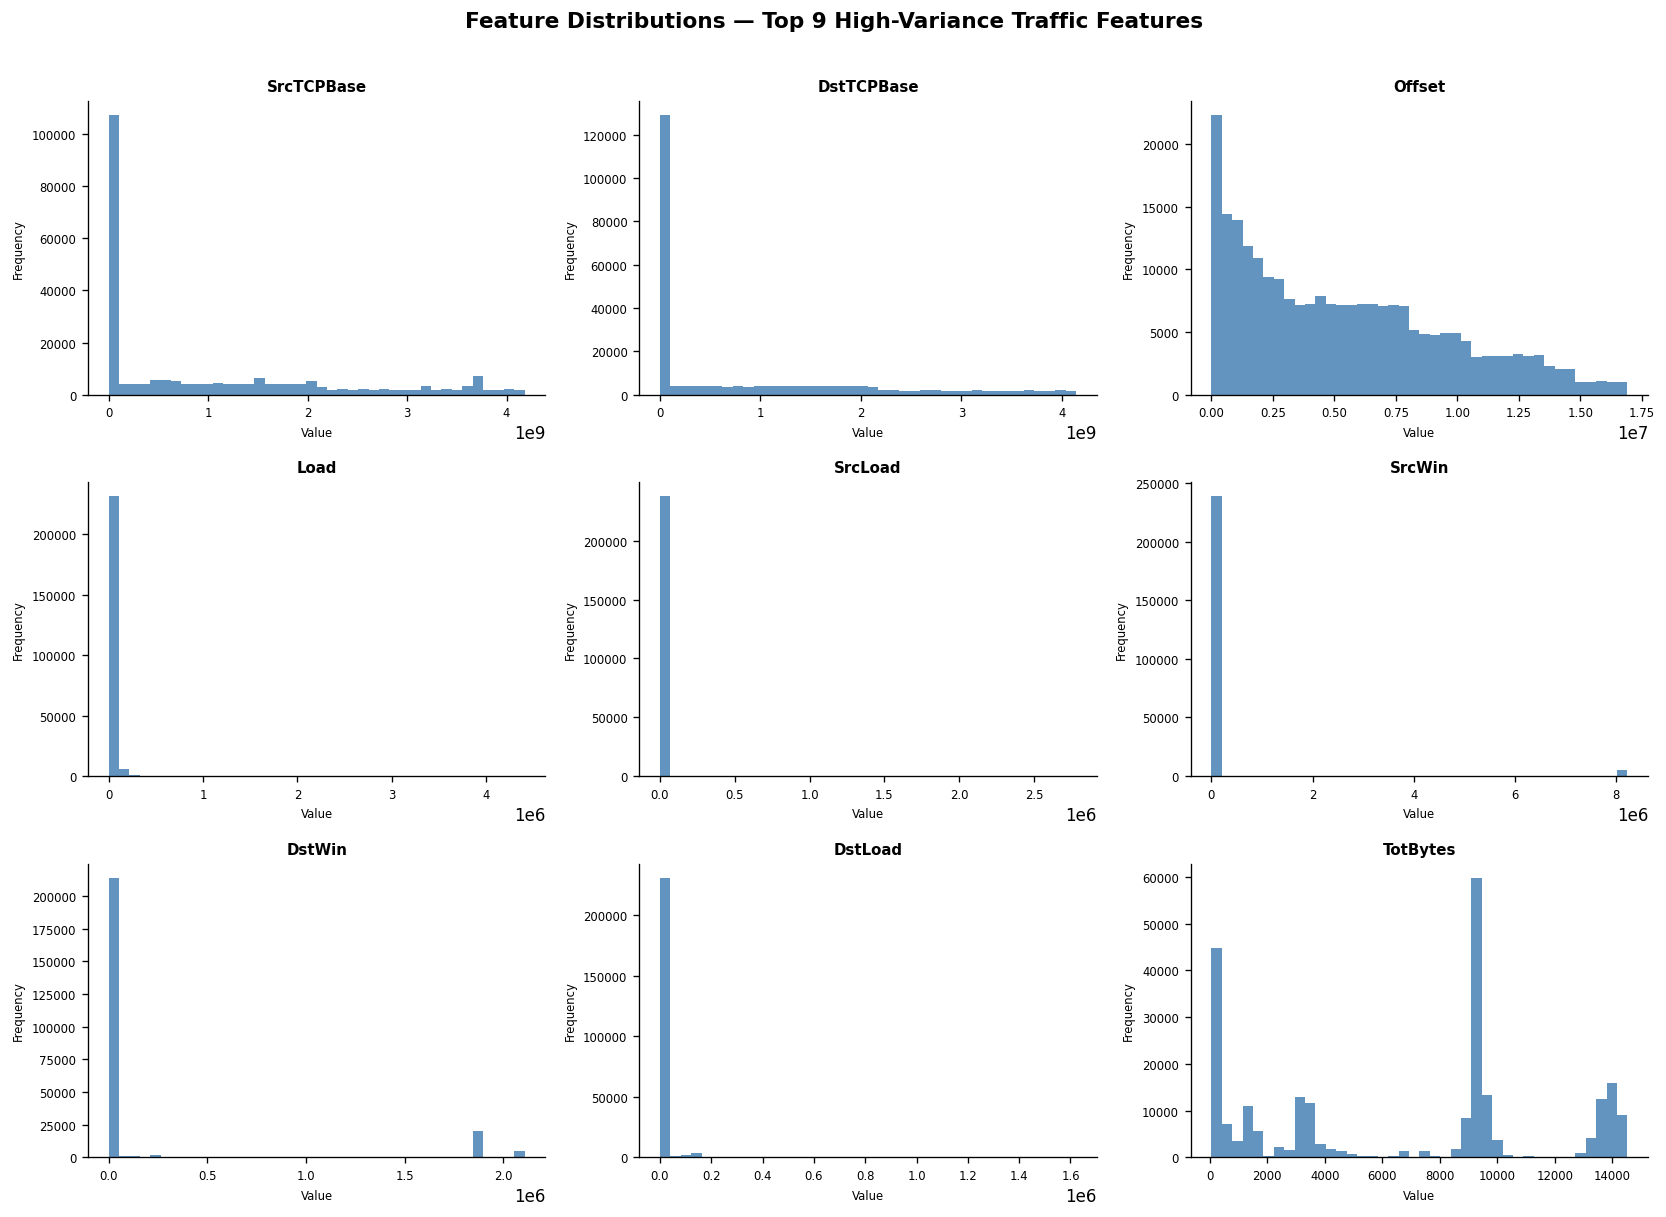

Chart 4 saved: /content/chart4_feature_distributions.png


In [9]:
# Chart 4 — Feature Distribution (Top 9 high-variance numeric features)
top9 = df[num_candidates].var().nlargest(9).index.tolist()

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(top9):
    data = df[col].dropna()
    # Clip extreme outliers to 99th percentile for visual clarity
    q99 = data.quantile(0.99)
    clipped = data[data <= (q99 if q99 > 0 else data.max())]
    axes[i].hist(clipped, bins=40, color='steelblue', edgecolor='none', alpha=0.85)
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].set_xlabel('Value', fontsize=7)
    axes[i].set_ylabel('Frequency', fontsize=7)
    axes[i].tick_params(labelsize=7)

fig.suptitle('Feature Distributions — Top 9 High-Variance Traffic Features', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
chart4_path = os.path.join(BASE_DIR, 'chart4_feature_distributions.png')
plt.savefig(chart4_path, bbox_inches='tight')
plt.show()
print(f'Chart 4 saved: {chart4_path}')

---
## T1.4 - Target Isolation and Stratified Splitting

Use `CategoryLabel` as the four-class target. Isolate every GeNIS label tier from the predictors to prevent target leakage. Split the official training file into 70% train, 15% validation, and 15% internal test before fitting any feature transformer. The official GeNIS test file remains separate for future independent evaluation.


In [11]:
# Step 1 - Separate target and all GeNIS label tiers
ALL_LABEL_COLS = ['BinaryLabel', 'CategoryLabel', 'SubCategoryLabel']

if 'CategoryLabel' not in df.columns:
    raise KeyError('CategoryLabel is required for the planned multiclass attack-category baseline.')

TARGET_COL = 'CategoryLabel'
labels_to_exclude = [c for c in ALL_LABEL_COLS if c in df.columns]

print(f'Selected target column: {TARGET_COL}')
print(f'All label tiers excluded from predictors: {labels_to_exclude}')

X_raw = df.drop(columns=labels_to_exclude).copy()
y_raw = df[TARGET_COL].astype(str).copy()

# Remove identifiers only; retain meaningful traffic and port features.
id_keywords = [
    'saddr', 'daddr', 'src_ip', 'dst_ip', 'mac', 'smac', 'dmac',
    'flow_id', 'record_id', 'timestamp', 'stime', 'ltime'
]
cols_to_drop = [
    c for c in X_raw.columns
    if any(kw == c.lower() or kw in c.lower() for kw in id_keywords)
]
preserve_keywords = [
    'pkt', 'byte', 'rate', 'load', 'loss', 'port', 'sport',
    'dport', 'dur', 'state', 'proto'
]
cols_to_drop = [
    c for c in cols_to_drop
    if not any(k in c.lower() for k in preserve_keywords)
]

print(f'Identifier columns dropped: {cols_to_drop}')
X_raw.drop(columns=cols_to_drop, inplace=True)

constant_cols = [
    c for c in X_raw.columns
    if X_raw[c].nunique(dropna=False) <= 1
]
print(f'Constant columns dropped: {constant_cols}')
X_raw.drop(columns=constant_cols, inplace=True)

# Split within each class so rare classes do not break stratification.
rng = np.random.default_rng(42)
y_values = y_raw.to_numpy()

train_positions = []
val_positions = []
test_positions = []
rare_classes = {}

for class_name in pd.unique(y_values):
    positions = np.flatnonzero(y_values == class_name)
    rng.shuffle(positions)
    n = len(positions)

    if n < 3:
        # Keep the class in training; it cannot be represented in all 3 splits.
        train_positions.extend(positions)
        rare_classes[str(class_name)] = n
        continue

    n_val = max(1, int(np.floor(0.15 * n)))
    n_test = max(1, int(np.floor(0.15 * n)))
    n_train = n - n_val - n_test

    train_positions.extend(positions[:n_train])
    val_positions.extend(positions[n_train:n_train + n_val])
    test_positions.extend(positions[n_train + n_val:])

# Shuffle rows within each split.
train_positions = np.asarray(train_positions, dtype=int)
val_positions = np.asarray(val_positions, dtype=int)
test_positions = np.asarray(test_positions, dtype=int)
rng.shuffle(train_positions)
rng.shuffle(val_positions)
rng.shuffle(test_positions)

X_train_raw = X_raw.iloc[train_positions].copy()
X_val_raw = X_raw.iloc[val_positions].copy()
X_test_raw = X_raw.iloc[test_positions].copy()

y_train_raw = y_raw.iloc[train_positions].copy()
y_val_raw = y_raw.iloc[val_positions].copy()
y_test_raw = y_raw.iloc[test_positions].copy()

if rare_classes:
    print(
        'Classes with fewer than 3 rows were assigned to training only '
        f'(not scored in validation/test): {rare_classes}'
    )

# Encode targets from training classes. All classes are present in training.
le_target = LabelEncoder()
y_train = le_target.fit_transform(y_train_raw)
y_val = le_target.transform(y_val_raw)
y_test = le_target.transform(y_test_raw)
class_names = le_target.classes_

print(f'\nTarget classes: {list(class_names)}')
print('Split sizes:')
for name, part in [
    ('Train', X_train_raw),
    ('Validation', X_val_raw),
    ('Internal test', X_test_raw)
]:
    print(f'  {name:<14}: {len(part):>8,} rows ({len(part)/len(X_raw)*100:.1f}%)')

print('Official GeNIS test file was not included in these splits.')

Selected target column: CategoryLabel
All label tiers excluded from predictors: ['BinaryLabel', 'CategoryLabel', 'SubCategoryLabel']
Identifier columns dropped: ['Ssaddr', 'Sdaddr']
Constant columns dropped: []
Classes with fewer than 3 rows were assigned to training only (not scored in validation/test): {'nan': 1}

Target classes: ['benign', 'bruteforce', 'dos', 'nan', 'recon']
Split sizes:
  Train         :  170,817 rows (70.0%)
  Validation    :   36,601 rows (15.0%)
  Internal test :   36,601 rows (15.0%)
Official GeNIS test file was not included in these splits.


---
## T1.5 — Feature Engineering (Training Split Only)

Missing value imputers and categorical encoders are **fitted strictly on `X_train_raw`**,
then transformed across validation and test sets without re-fitting. This prevents data leakage.

In [12]:
numeric_cols = X_train_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols     = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()

X_train_clean = X_train_raw.copy()
X_val_clean   = X_val_raw.copy()
X_test_clean  = X_test_raw.copy()

# 1. Numeric Imputation — Calculate medians on TRAINING split only
train_medians = X_train_raw[numeric_cols].median()
X_train_clean[numeric_cols] = X_train_clean[numeric_cols].fillna(train_medians)
X_val_clean[numeric_cols]   = X_val_clean[numeric_cols].fillna(train_medians)
X_test_clean[numeric_cols]  = X_test_clean[numeric_cols].fillna(train_medians)

# 2. Categorical Imputation and Encoding — Fitted on TRAINING split only
cat_encoders = {}
for col in cat_cols:
    train_mode = X_train_raw[col].mode()[0] if not X_train_raw[col].empty else 'missing'
    X_train_clean[col].fillna(train_mode, inplace=True)
    X_val_clean[col].fillna(train_mode, inplace=True)
    X_test_clean[col].fillna(train_mode, inplace=True)

    le = LabelEncoder()
    X_train_clean[col] = le.fit_transform(X_train_clean[col].astype(str))
    cat_encoders[col] = le

    # Safe transform for Val/Test handling any unseen categories
    known_classes = set(le.classes_)
    default_class = le.classes_[0]
    X_val_clean[col]  = X_val_clean[col].map(lambda x: x if x in known_classes else default_class)
    X_test_clean[col] = X_test_clean[col].map(lambda x: x if x in known_classes else default_class)
    X_val_clean[col]  = le.transform(X_val_clean[col].astype(str))
    X_test_clean[col] = le.transform(X_test_clean[col].astype(str))

print('Feature Engineering complete (Fitted on Training Set Only):')
print(f'  Numeric features imputed : {len(numeric_cols)}')
print(f'  Categorical features encoded : {len(cat_cols)}')
print(f'  Remaining missing in Train : {X_train_clean.isnull().sum().sum()}')
print(f'  Remaining missing in Val   : {X_val_clean.isnull().sum().sum()}')
print(f'  Remaining missing in Test  : {X_test_clean.isnull().sum().sum()}')

Feature Engineering complete (Fitted on Training Set Only):
  Numeric features imputed : 59
  Categorical features encoded : 23
  Remaining missing in Train : 0
  Remaining missing in Val   : 0
  Remaining missing in Test  : 0


---
## T1.6 — Normalization (Training Split Only)

We fit `MinMaxScaler` **only on the training split** to establish scale bounds $[0, 1]$.
Validation and test sets are transformed using the fitted scaler, with no re-fitting.

In [13]:
feature_cols = X_train_clean.columns.tolist()

# Fit scaler on training split ONLY
scaler = MinMaxScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_clean), columns=feature_cols)
X_val   = pd.DataFrame(scaler.transform(X_val_clean),       columns=feature_cols)
X_test  = pd.DataFrame(scaler.transform(X_test_clean),      columns=feature_cols)

print('Min-Max Normalization applied strictly without data leakage.')
print(f'X_train shape : {X_train.shape}')
print(f'X_val shape   : {X_val.shape}')
print(f'X_test shape  : {X_test.shape}')
print(f'Train bounds  : min={X_train.min().min():.4f}, max={X_train.max().max():.4f}')
print(f'Test range    : min={X_test.min().min():.4f}, max={X_test.max().max():.4f}')

Min-Max Normalization applied strictly without data leakage.
X_train shape : (170817, 82)
X_val shape   : (36601, 82)
X_test shape  : (36601, 82)
Train bounds  : min=0.0000, max=1.0000
Test range    : min=0.0000, max=63.2500


---
## T1.7 - Class Imbalance Report

Report the training-split counts and percentages for every `CategoryLabel`. Identify the most frequent and least frequent classes factually. Benign traffic is a class, not an attack; whether an attack class is underrepresented is described separately from benign traffic.


In [14]:
# Class counts on training data
counts_series = pd.Series(y_train).value_counts().reindex(range(len(class_names)), fill_value=0)
counts = counts_series.to_numpy()
names = [str(name) for name in class_names]
total = int(counts.sum())
separator = '=' * 75
print(separator)
print('NETGUARDAI - CLASS DISTRIBUTION REPORT')
print('GeNIS official training partition, internal training split | T1.7')
print(separator)
print(f'{"Class":<25} {"Count":>12} {"Percentage":>12}')
for name, count in zip(names, counts):
    print(f'{name:<25} {count:>12,} {count/total*100:>11.3f}%')

majority_idx = int(np.argmax(counts))
rarest_idx = int(np.argmin(counts))
ratio = counts[majority_idx] / counts[rarest_idx] if counts[rarest_idx] else float('inf')
attack_indices = [i for i, name in enumerate(names) if name.lower() != 'benign']
rarest_attack_idx = min(attack_indices, key=lambda i: counts[i]) if attack_indices else None
print(f"\nMost frequent class: {names[majority_idx]} ({counts[majority_idx]:,})")
print(f'Least frequent class: {names[rarest_idx]} ({counts[rarest_idx]:,})')
print(f'Most-to-least frequent class ratio: {ratio:.2f}:1')
if rarest_attack_idx is not None:
    print(f'Least frequent attack category: {names[rarest_attack_idx]} ({counts[rarest_attack_idx]:,})')
print('These counts describe imbalance; they do not by themselves establish baseline failure or augmentation benefit.')
print(separator)

NETGUARDAI - CLASS DISTRIBUTION REPORT
GeNIS official training partition, internal training split | T1.7
Class                            Count   Percentage
benign                          12,577       7.363%
bruteforce                       8,371       4.901%
dos                            136,954      80.176%
nan                                  1       0.001%
recon                           12,914       7.560%

Most frequent class: dos (136,954)
Least frequent class: nan (1)
Most-to-least frequent class ratio: 136954.00:1
Least frequent attack category: nan (1)
These counts describe imbalance; they do not by themselves establish baseline failure or augmentation benefit.


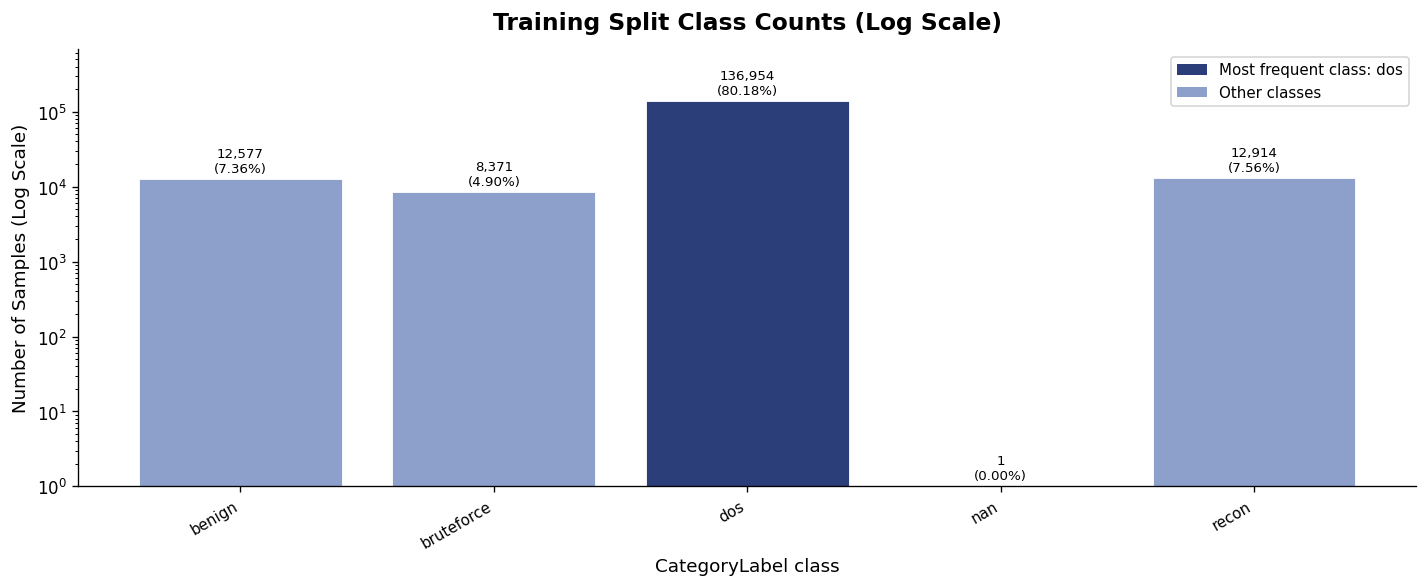

Chart 5 saved: /content/chart5_class_imbalance_report.png


In [15]:
# Class counts in target-class order; highlight only the actual largest class.
majority_idx = int(np.argmax(counts))
fig, ax = plt.subplots(figsize=(12, 5))
bar_colors = ['#2c3e7a' if i == majority_idx else '#8da0cb' for i in range(len(names))]
bars = ax.bar(names, counts, color=bar_colors, edgecolor='white', linewidth=0.5)
ax.set_yscale('log')
for bar, val in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, val * 1.15,
            f'{val:,}\n({val/total*100:.2f}%)', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#2c3e7a', label=f'Most frequent class: {names[majority_idx]}'),
    Patch(facecolor='#8da0cb', label='Other classes')
], fontsize=9)
ax.set_title('Training Split Class Counts (Log Scale)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('CategoryLabel class', fontsize=11)
ax.set_ylabel('Number of Samples (Log Scale)', fontsize=11)
ax.set_ylim(bottom=1, top=counts.max() * 5)
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.tight_layout()
chart5_path = os.path.join(BASE_DIR, 'chart5_class_imbalance_report.png')
plt.savefig(chart5_path, bbox_inches='tight')
plt.show()
print(f'Chart 5 saved: {chart5_path}')


---
## T1.8 - Baseline Benchmark (No Augmentation)

Train a Random Forest on the unaugmented training split and evaluate on the real internal held-out test split. Report measured per-class F1 and recall without presuming which classes will be difficult. These are internal results from the official training file; use the untouched official test partition for a later independent evaluation.


In [16]:
print('Training baseline Random Forest classifier on unaugmented data...')
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)
y_pred = rf_baseline.predict(X_test)
print('Training complete. Evaluating on held-out test partition...')

Training baseline Random Forest classifier on unaugmented data...
Training complete. Evaluating on held-out test partition...


In [18]:
from sklearn.metrics import classification_report, f1_score, recall_score

report_labels = sorted(set(y_test) | set(y_pred))
report_names = [str(class_names[i]) for i in report_labels]

print('=' * 65)
print(f'NETGUARDAI - BASELINE MODEL RESULTS (NO AUGMENTATION)')
print(f'Random Forest | Internal held-out split ({X_test.shape[0]:,} samples) | T1.8')
print('=' * 65)

print(classification_report(
    y_test,
    y_pred,
    labels=report_labels,
    target_names=report_names,
    digits=4,
    zero_division=0
))

macro_f1 = f1_score(
    y_test, y_pred, labels=report_labels, average='macro', zero_division=0
)
macro_rec = recall_score(
    y_test, y_pred, labels=report_labels, average='macro', zero_division=0
)

print(f'Macro F1:    {macro_f1:.4f}')
print(f'Macro Recall: {macro_rec:.4f}')

NETGUARDAI - BASELINE MODEL RESULTS (NO AUGMENTATION)
Random Forest | Internal held-out split (36,601 samples) | T1.8
              precision    recall  f1-score   support

      benign     1.0000    1.0000    1.0000      2695
  bruteforce     1.0000    1.0000    1.0000      1793
         dos     1.0000    1.0000    1.0000     29347
       recon     1.0000    1.0000    1.0000      2766

    accuracy                         1.0000     36601
   macro avg     1.0000    1.0000    1.0000     36601
weighted avg     1.0000    1.0000    1.0000     36601

Macro F1:    1.0000
Macro Recall: 1.0000


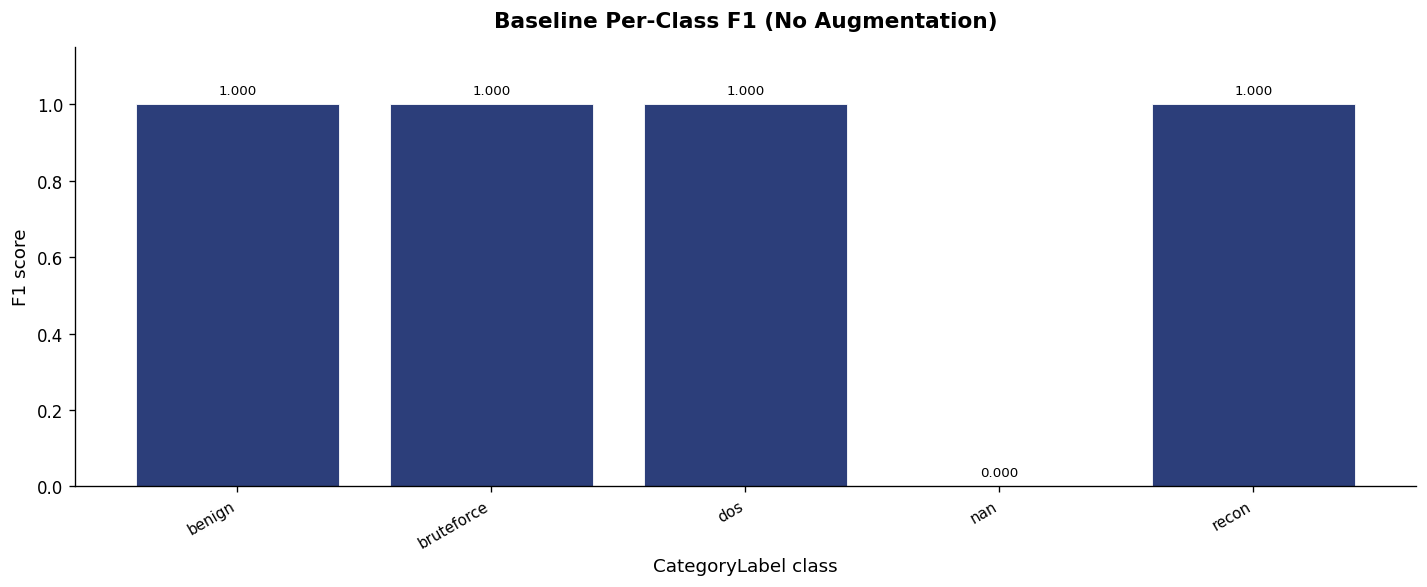

Chart 6 saved: /content/chart6_baseline_f1_scores.png


In [19]:
# Per-class F1 scores; color consistently without implying a universal pass threshold.
per_class_f1 = f1_score(y_test, y_pred, average=None, labels=np.arange(len(class_names)), zero_division=0)
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(class_names, per_class_f1, color='#2c3e7a', edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, per_class_f1):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.3f}', ha='center', va='bottom', fontsize=8)
ax.set_title('Baseline Per-Class F1 (No Augmentation)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('CategoryLabel class', fontsize=11)
ax.set_ylabel('F1 score', fontsize=11)
ax.set_ylim(0, 1.15)
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.tight_layout()
chart6_path = os.path.join(BASE_DIR, 'chart6_baseline_f1_scores.png')
plt.savefig(chart6_path, bbox_inches='tight')
plt.show()
print(f'Chart 6 saved: {chart6_path}')


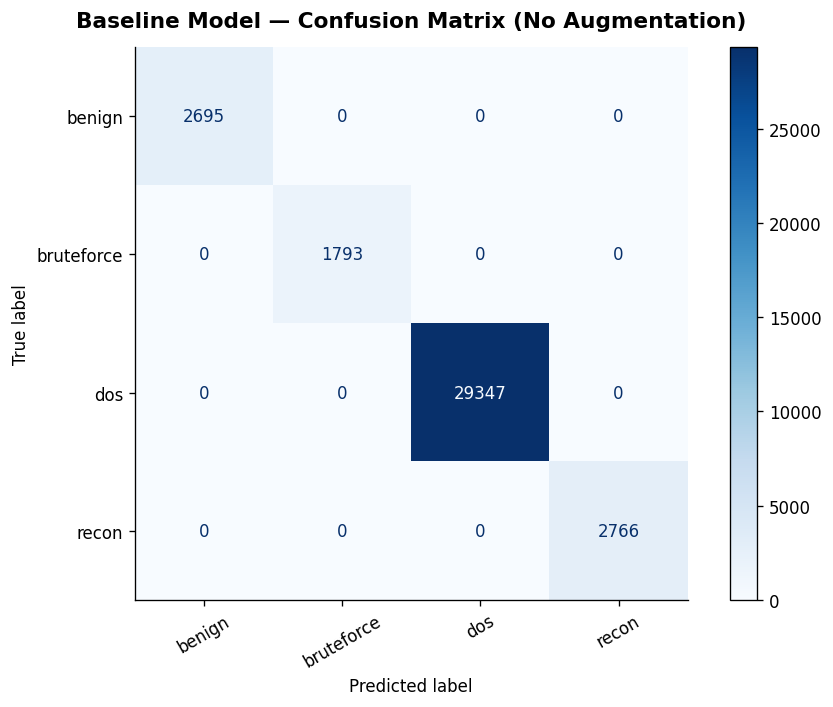

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Include only classes present in the test labels or predictions
cm_labels = sorted(set(y_test) | set(y_pred))
cm_names = [str(class_names[i]) for i in cm_labels]

cm = confusion_matrix(y_test, y_pred, labels=cm_labels)

fig, ax = plt.subplots(
    figsize=(max(8, len(cm_names) * 1.5), max(6, len(cm_names) * 1.2))
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cm_names
)
disp.plot(ax=ax, colorbar=True, cmap='Blues', xticks_rotation=30)

ax.set_title(
    'Baseline Model — Confusion Matrix (No Augmentation)',
    fontsize=13,
    fontweight='bold',
    pad=12
)
plt.tight_layout()
plt.show()

---
## Module 1 - Final Summary

This notebook prepares development splits and a no-augmentation baseline. It does not establish in advance that a class is poorly detected or that augmentation will improve results. The official GeNIS test partition remains reserved for independent evaluation.


In [22]:
print('=' * 65)
print('NETGUARDAI - MODULE 1 DEVELOPMENT PIPELINE')
print('=' * 65)
print('[DONE] GeNIS 60-second official training partition loaded')
print('[DONE] Official test partition kept separate')
print('[DONE] CategoryLabel target isolated; all other label tiers excluded from predictors')
print('[DONE] Internal 70/15/15 split created before fitting feature transformers')
print('[DONE] Imputation, encoding, and scaling fitted on training data only')
print('[DONE] Class counts and unaugmented Random Forest metrics reported')
print('\nDevelopment split shapes:')
print(f'  Train: {X_train.shape} / {y_train.shape}')
print(f'  Validation: {X_val.shape} / {y_val.shape}')
print(f'  Internal test: {X_test.shape} / {y_test.shape}')
print(f'Official independent test file retained at: {official_test_csv}')
print('Capture/scenario grouping cannot be verified unless the source provides a suitable group identifier.')

NETGUARDAI - MODULE 1 DEVELOPMENT PIPELINE
[DONE] GeNIS 60-second official training partition loaded
[DONE] Official test partition kept separate
[DONE] CategoryLabel target isolated; all other label tiers excluded from predictors
[DONE] Internal 70/15/15 split created before fitting feature transformers
[DONE] Imputation, encoding, and scaling fitted on training data only
[DONE] Class counts and unaugmented Random Forest metrics reported

Development split shapes:
  Train: (170817, 82) / (170817,)
  Validation: (36601, 82) / (36601,)
  Internal test: (36601, 82) / (36601,)
Official independent test file retained at: /content/genis_data/4-preprocessed/genis-60-sec-test.csv
Capture/scenario grouping cannot be verified unless the source provides a suitable group identifier.


In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)

# Include classes present in the held-out test labels or model predictions.
evaluated_labels = sorted(set(y_test) | set(y_pred))
evaluated_names = [str(class_names[i]) for i in evaluated_labels]

print('=' * 72)
print('NETGUARDAI — RANDOM FOREST BASELINE METRICS')
print(f'Internal held-out test set: {len(y_test):,} samples')
print(f'Classes evaluated: {len(evaluated_labels)} of {len(class_names)}')
print('=' * 72)

missing_labels = sorted(set(range(len(class_names))) - set(evaluated_labels))
if missing_labels:
    missing_names = [str(class_names[i]) for i in missing_labels]
    print(f'Not evaluated (no test samples or predictions): {missing_names}')

print(f'\nAccuracy:          {accuracy_score(y_test, y_pred):.4f}')
print(f'Macro precision:   {precision_score(y_test, y_pred, labels=evaluated_labels, average="macro", zero_division=0):.4f}')
print(f'Macro recall:      {recall_score(y_test, y_pred, labels=evaluated_labels, average="macro", zero_division=0):.4f}')
print(f'Macro F1:          {f1_score(y_test, y_pred, labels=evaluated_labels, average="macro", zero_division=0):.4f}')
print(f'Weighted F1:       {f1_score(y_test, y_pred, labels=evaluated_labels, average="weighted", zero_division=0):.4f}')

print('\nPer-class report:')
print(classification_report(
    y_test,
    y_pred,
    labels=evaluated_labels,
    target_names=evaluated_names,
    digits=4,
    zero_division=0
))

NETGUARDAI — RANDOM FOREST BASELINE METRICS
Internal held-out test set: 36,601 samples
Classes evaluated: 4 of 5
Not evaluated (no test samples or predictions): ['nan']

Accuracy:          1.0000
Macro precision:   1.0000
Macro recall:      1.0000
Macro F1:          1.0000
Weighted F1:       1.0000

Per-class report:
              precision    recall  f1-score   support

      benign     1.0000    1.0000    1.0000      2695
  bruteforce     1.0000    1.0000    1.0000      1793
         dos     1.0000    1.0000    1.0000     29347
       recon     1.0000    1.0000    1.0000      2766

    accuracy                         1.0000     36601
   macro avg     1.0000    1.0000    1.0000     36601
weighted avg     1.0000    1.0000    1.0000     36601

